# Capacidad de almacenamiento para la temporada alta: RetailCo

**¿Le alcanza el espacio a cada centro de distribución en la temporada alta y, si no, cuántas posiciones adicionales hay que pedir?**

**Autor:** Felipe Vásquez Torres · [LinkedIn](https://www.linkedin.com/in/felipe-vasquez-torres) · [Portafolio](https://fvt1999pipe-eng.github.io)

> Caso de estudio basado en un análisis real de capacidad para un comité S&OP. La empresa, los centros y todos los datos son **ficticios** y fueron generados para este proyecto: no corresponden a ninguna compañía.

## Contexto y objetivo

RetailCo es una cadena de tiendas de conveniencia abastecida por 5 centros de distribución: 4 propios y 1 operador logístico (OPL) de frío. En temporada alta el **recibo** (cajas que entran) crece mucho más que el **alistamiento** (piezas que salen hacia las tiendas), y la bodega se llena con inventario de temporada.

El comité S&OP de capacidades necesita decidir, antes de noviembre, si pide posiciones adicionales y cuántas. El objetivo es proyectar la ocupación semanal de cada centro entre la S43 de 2025 y la S13 de 2026 con un método validado contra el histórico, y convertirla en posiciones faltantes y recomendaciones.

## Contenido

1. Calidad de los datos
2. Precisión del forecast (SQL)
3. Crecimiento de temporada
4. Calibración del modelo de flujo
5. Backtest y validación del atajo de 33 cajas por ubicación
6. Proyección de temporada y sensibilidad
7. Alistamiento, categorías y versiones del forecast
8. Semáforo de la red, conclusiones y recomendaciones

In [1]:
import sqlite3
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

DATA = Path("data")
IMG = Path("img"); IMG.mkdir(exist_ok=True)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

# Paleta y estilo de los gráficos
COLORES = {"CD-Norte": "#2a78d6", "CD-Centro": "#eb6834", "CD-Oriente": "#1baf7a",
           "CD-Bebidas": "#eda100", "OPL-Frio": "#6250d6"}
GRIS, TINTA, TINTA2 = "#d9d8d4", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": "#ecebe8", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

## 1. Calidad de los datos

| Archivo | Contenido |
|---|---|
| `historico_semanal.csv` | Recibo y alistamiento (forecast y real) y ocupación por centro y semana, S1 2024 – S42 2025 |
| `forecast_temporada.csv` | Forecast de temporada por centro y categoría en formato ancho, versiones de septiembre y octubre |
| `centros_distribucion.csv` | Posiciones, cajas por estiba, piezas por bulto y capacidad de alistamiento por centro |

In [2]:
historico_raw = pd.read_csv(DATA / "historico_semanal.csv")
forecast_raw = pd.read_csv(DATA / "forecast_temporada.csv")
cds = pd.read_csv(DATA / "centros_distribucion.csv")

for nombre, df in [("historico", historico_raw), ("forecast", forecast_raw), ("centros", cds)]:
    print(f"{nombre}: {df.shape[0]} filas x {df.shape[1]} columnas")
historico_raw.info()
historico_raw.head()

historico: 477 filas x 8 columnas
forecast: 128 filas x 27 columnas
centros: 5 filas x 7 columnas
<class 'pandas.DataFrame'>
RangeIndex: 477 entries, 0 to 476
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cd               477 non-null    str    
 1   anio             477 non-null    int64  
 2   semana           477 non-null    int64  
 3   cajas_forecast   477 non-null    int64  
 4   cajas_real       469 non-null    float64
 5   piezas_forecast  477 non-null    int64  
 6   piezas_real      474 non-null    float64
 7   ocupacion        471 non-null    float64
dtypes: float64(3), int64(4), str(1)
memory usage: 29.9 KB


,cd,anio,semana,cajas_forecast,cajas_real,piezas_forecast,piezas_real,ocupacion
0,CD-Norte,2024,28,46961,47673.0,409913,420484.0,0.6759
1,CD-Centro,2024,12,18572,19680.0,152362,144052.0,0.5360
2,CD NORTE,2025,16,56770,55469.0,452131,460259.0,0.7496
3,CD-Bebidas,2024,46,18196,23454.0,37843,35696.0,0.9186
4,CD-Bebidas,2024,16,14515,15865.0,41655,41139.0,0.6885


In [3]:
cds

,cd,tipo,ciudad,posiciones,cajas_por_estiba,piezas_por_bulto,capacidad_alistamiento_semana
0,CD-Norte,Propio,Ciudad Norte,4800,40,9.6,580000
1,CD-Centro,Propio,Ciudad Centro,1900,38,8.4,165000
2,CD-Oriente,Propio,Ciudad Oriente,1300,30,8.6,105000
3,CD-Bebidas,Propio,Ciudad Norte,1500,90,2.8,50000
4,OPL-Frio,OPL,Ciudad Centro,350,45,7.0,21000


In [4]:
# Revisión de calidad: nombres, escalas, duplicados y nulos
print(historico_raw["cd"].value_counts(), "\n")
ocup = pd.to_numeric(historico_raw["ocupacion"], errors="coerce")
print("Ocupación > 1.5 (escala 0-100):", (ocup > 1.5).sum())
print("Duplicados por centro y semana:", historico_raw.duplicated(["cd", "anio", "semana"]).sum())
print("\nNulos por columna:\n", historico_raw.isna().sum())

cd
CD-Bebidas    96
CD-Oriente    96
CD-Norte      85
CD-Centro     84
OPL-Frio      83
CD NORTE      11
OPL-Frío      11
cd-centro     11
Name: count, dtype: int64 

Ocupación > 1.5 (escala 0-100): 42
Duplicados por centro y semana: 7

Nulos por columna:
 cd                 0
anio               0
semana             0
cajas_forecast     0
cajas_real         8
piezas_forecast    0
piezas_real        3
ocupacion          6
dtype: int64


In [5]:
historico = historico_raw.copy()

# 1. Nombres de centro: un solo formato
def normalizar_cd(nombre):
    n = nombre.strip().upper().replace(" ", "-").replace("Í", "I")
    return {"CD-NORTE": "CD-Norte", "CD-CENTRO": "CD-Centro", "CD-ORIENTE": "CD-Oriente",
            "CD-BEBIDAS": "CD-Bebidas", "OPL-FRIO": "OPL-Frio"}[n]
historico["cd"] = historico["cd"].map(normalizar_cd)

# 2. Ocupación en una sola escala (0 a 1)
historico["ocupacion"] = pd.to_numeric(historico["ocupacion"], errors="coerce")
historico.loc[historico["ocupacion"] > 1.5, "ocupacion"] /= 100

# 3. Duplicados: se conserva la fila con más datos
historico["_completos"] = historico.notna().sum(axis=1)
historico = (historico.sort_values("_completos", ascending=False)
             .drop_duplicates(["cd", "anio", "semana"])
             .drop(columns="_completos")
             .sort_values(["cd", "anio", "semana"]).reset_index(drop=True))
print("Filas después de quitar duplicados:", len(historico))
print("Semanas por centro:", historico.groupby("cd").size().unique())

Filas después de quitar duplicados: 470
Semanas por centro: [94]


In [6]:
# 4. Huecos: ocupación faltante y recibo real faltante
print(historico[historico["ocupacion"].isna()][["cd", "anio", "semana"]], "\n")
hueco = historico[historico["cajas_real"].isna()]
print(hueco[["cd", "anio", "semana", "cajas_forecast"]])

             cd  anio  semana
110   CD-Centro  2024      17
270    CD-Norte  2025      31
341  CD-Oriente  2025       8 

             cd  anio  semana  cajas_forecast
353  CD-Oriente  2025      20           13339
354  CD-Oriente  2025      21            9823
355  CD-Oriente  2025      22           11756
356  CD-Oriente  2025      23           11416
357  CD-Oriente  2025      24           13880
358  CD-Oriente  2025      25            9459
359  CD-Oriente  2025      26           10047
360  CD-Oriente  2025      27           11333


In [7]:
# Ocupación faltante: interpolación lineal dentro de cada centro (semanas aisladas)
historico["ocup_imputada"] = historico["ocupacion"].isna()
historico["ocupacion"] = historico.groupby("cd")["ocupacion"].transform(lambda s: s.interpolate())

# Recibo faltante: forecast x cumplimiento mediano del centro en las 8 semanas previas al hueco
historico["recibo_imputado"] = historico["cajas_real"].isna()
for cd_, g in historico[historico["recibo_imputado"]].groupby("cd"):
    previas = historico[(historico["cd"] == cd_) & ~historico["recibo_imputado"] &
                        (historico.index < g.index.min())].tail(8)
    factor = (previas["cajas_real"] / previas["cajas_forecast"]).median()
    historico.loc[g.index, "cajas_real"] = (g["cajas_forecast"] * factor).round()
    print(f"{cd_}: {len(g)} semanas completadas con forecast x {factor:.3f}")

CD-Oriente: 8 semanas completadas con forecast x 1.042


In [8]:
# 5. Datos sospechosos: se marcan y no se corrigen
g = historico.groupby("cd")
historico["semana_copiada"] = (historico["cajas_real"] == g["cajas_real"].shift()) & \
                              (historico["piezas_real"] == g["piezas_real"].shift())
historico["valor_redondo"] = (historico[["cajas_forecast", "piezas_forecast"]] % 10000 == 0).any(axis=1)
print(historico[historico["semana_copiada"] | historico["valor_redondo"]]
      [["cd", "anio", "semana", "cajas_real", "piezas_real", "piezas_forecast"]])

historico[["cajas_real", "piezas_real"]] = historico[["cajas_real", "piezas_real"]].astype(int)
historico["mes"] = [date.fromisocalendar(a, s, 1).month for a, s in zip(historico["anio"], historico["semana"])]

            cd  anio  semana  cajas_real  piezas_real  piezas_forecast
129  CD-Centro  2024      36     15795.0     124778.0           132355
199   CD-Norte  2024      12     60085.0     479438.0           400000


In [9]:
# Forecast de temporada: de formato ancho (una columna por semana) a formato largo
semanas = [c for c in forecast_raw.columns if c[:2] == "20"]
forecast = (forecast_raw.melt(id_vars=["version", "cd", "categoria", "metrica"], value_vars=semanas,
                              var_name="anio_semana", value_name="valor")
            .dropna(subset=["valor"]))
forecast["anio"] = forecast["anio_semana"].str[:4].astype(int)
forecast["semana"] = forecast["anio_semana"].str[-2:].astype(int)
forecast = (forecast.pivot_table(index=["version", "cd", "categoria", "anio", "semana"],
                                 columns="metrica", values="valor", aggfunc="sum")
            .reset_index().rename_axis(columns=None))
forecast["mes"] = [date.fromisocalendar(a, s, 1).month for a, s in zip(forecast["anio"], forecast["semana"])]
forecast.groupby("version")["semana"].agg(["count", "min", "max"])

,count,min,max
version,,,
2025-09,320,43,52
2025-10,736,1,52


### Conclusión: ¿podemos confiar en los datos?

**Sí, después de seis correcciones.** El histórico pasa de 477 a 470 filas: 5 centros × 94 semanas, sin duplicados.

| Problema | Decisión |
|---|---|
| 33 filas con el nombre del centro escrito de otra forma (`CD NORTE`, `cd-centro `, `OPL-Frío`) | Se unificaron |
| 42 valores de ocupación del OPL en escala 0–100 desde 2025 | Se dividieron entre 100 |
| 7 filas duplicadas (4 exactas y 3 incompletas) | Se conservó la fila con más datos |
| 3 semanas aisladas sin ocupación | Interpolación lineal, marcadas como imputadas |
| 8 semanas sin recibo real en CD-Oriente (S20–S27 de 2025) | Forecast × 1,042, el cumplimiento mediano de las 8 semanas previas; marcadas |
| Una semana copiada (CD-Centro, S36 de 2024) y un forecast redondo de 400.000 piezas (CD-Norte, S12 de 2024) | Se marcaron y no se corrigieron |

Las semanas imputadas o copiadas no se usan para calibrar el modelo. El forecast de temporada quedó en formato largo: la versión de septiembre cubre S43–S52 y la de octubre S43 de 2025 – S13 de 2026, en 7 categorías.

## 2. Precisión del forecast (SQL)

Cumplimiento = real ÷ forecast. Un mes solo se reporta si tiene al menos 4 semanas. Semáforo: verde entre 95 % y 105 %, rojo sobre 105 % y café bajo 95 %.

In [10]:
# ---------------- 2. Precisión del forecast (SQL) ----------------
con = sqlite3.connect(":memory:")
historico.to_sql("historico", con, index=False)

consulta = """
WITH mensual AS (
    SELECT cd, anio, mes,
           COUNT(*)              AS semanas,
           SUM(cajas_real)       AS cajas_real,
           SUM(cajas_forecast)   AS cajas_forecast,
           SUM(piezas_real)      AS piezas_real,
           SUM(piezas_forecast)  AS piezas_forecast
    FROM historico
    GROUP BY cd, anio, mes
)
SELECT cd, anio, mes, semanas,
       ROUND(100.0 * cajas_real  / cajas_forecast, 1)  AS cumpl_recibo,
       ROUND(100.0 * piezas_real / piezas_forecast, 1) AS cumpl_alistamiento
FROM mensual
WHERE semanas >= 4
ORDER BY cd, anio, mes
"""
cumplimiento = pd.read_sql(consulta, con)

def semaforo(x):
    return "Verde" if 95 <= x <= 105 else ("Rojo" if x > 105 else "Café")
cumplimiento["semaforo_recibo"] = cumplimiento["cumpl_recibo"].map(semaforo)
cumplimiento.tail(10)

,cd,anio,mes,semanas,cumpl_recibo,cumpl_alistamiento,semaforo_recibo
95,OPL-Frio,2024,12,4,112.3,100.5,Rojo
96,OPL-Frio,2025,1,4,100.1,98.5,Verde
97,OPL-Frio,2025,2,4,100.3,99.4,Verde
98,OPL-Frio,2025,3,5,108.2,98.2,Rojo
99,OPL-Frio,2025,4,4,102.4,96.9,Verde
100,OPL-Frio,2025,5,4,103.2,100.3,Verde
101,OPL-Frio,2025,6,5,102.3,99.9,Verde
102,OPL-Frio,2025,7,4,104.6,99.4,Verde
103,OPL-Frio,2025,8,4,106.1,99.3,Rojo
104,OPL-Frio,2025,9,5,104.7,99.1,Verde


In [11]:
# Cumplimiento por temporada: temporada pasada (S43 2024 - S13 2025), resto del año y arranque de la actual
consulta_temporada = """
SELECT cd,
       CASE WHEN (anio = 2024 AND semana >= 43) OR (anio = 2025 AND semana <= 13) THEN 'Temporada 2024-25'
            WHEN anio = 2025 AND semana BETWEEN 36 AND 42 THEN 'Sep-oct 2025'
            ELSE 'Resto del año' END AS periodo,
       ROUND(100.0 * SUM(cajas_real)  / SUM(cajas_forecast), 1)  AS cumpl_recibo,
       ROUND(100.0 * SUM(piezas_real) / SUM(piezas_forecast), 1) AS cumpl_alistamiento
FROM historico
GROUP BY cd, periodo
"""
cumpl_periodo = pd.read_sql(consulta_temporada, con)
tabla_cumpl = cumpl_periodo.pivot(index="cd", columns="periodo", values=["cumpl_recibo", "cumpl_alistamiento"])
tabla_cumpl

cumpl_recibo                                cumpl_alistamiento                               
periodo    Resto del año Sep-oct 2025 Temporada 2024-25      Resto del año Sep-oct 2025 Temporada 2024-25
cd                                                                                                       
CD-Bebidas         103.1        112.6             109.8               98.2         98.5             100.0
CD-Centro          103.8        105.8             114.3               98.2         97.9              99.7
CD-Norte           104.1        112.7             111.6               99.1         97.4              98.6
CD-Oriente         103.4        107.9             109.9               99.9        100.8              99.5
OPL-Frio           105.0        110.9             114.0               98.6         99.4              98.8

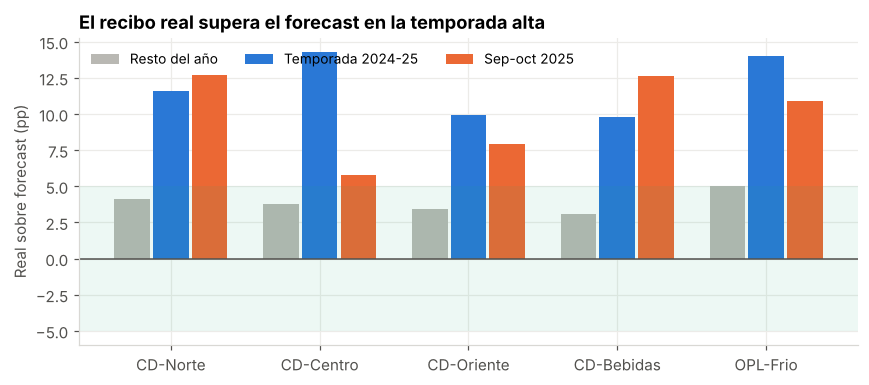

In [12]:
orden = ["CD-Norte", "CD-Centro", "CD-Oriente", "CD-Bebidas", "OPL-Frio"]
t = cumpl_periodo.pivot(index="cd", columns="periodo", values="cumpl_recibo").loc[orden]
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(orden)); w = 0.26
for i, (per, col) in enumerate([("Resto del año", "#b9b8b3"), ("Temporada 2024-25", "#2a78d6"), ("Sep-oct 2025", "#eb6834")]):
    ax.bar(x + (i - 1) * w, t[per] - 100, w * 0.92, label=per, color=col)
ax.axhline(0, color=TINTA2, lw=1)
ax.axhspan(-5, 5, color="#1baf7a", alpha=0.08, lw=0)
ax.set_xticks(x, orden); ax.set_ylabel("Real sobre forecast (pp)")
ax.set_title("El recibo real supera el forecast en la temporada alta")
ax.legend(ncol=3, loc="upper left", fontsize=9)
plt.tight_layout(); plt.savefig(IMG / "cumplimiento_recibo.png"); plt.show()

### Conclusión: ¿qué tan preciso es el forecast?

**El alistamiento se proyecta bien; el recibo no.** El alistamiento real queda entre 97 % y 101 % del forecast en todos los periodos.

El recibo real supera el forecast entre 3 % y 5 % en el resto del año, pero entre **10 % y 14 % en la temporada pasada** y entre **6 % y 13 % en septiembre y octubre de 2025**. CD-Norte y CD-Bebidas ya están 13 puntos por encima en el arranque de esta temporada. Si el patrón se repite, la proyección con el forecast subestima la ocupación: por eso la sección 6 incluye una sensibilidad al recibo.

## 3. Crecimiento de temporada

Promedio semanal de la S45 a la S51 del forecast de octubre frente al promedio semanal real de septiembre de 2025. La **brecha** es la variación del recibo menos la del alistamiento: si es positiva, la bodega acumula inventario.

In [13]:
# ---------------- 3. Crecimiento de temporada ----------------
fc_oct = forecast[forecast["version"] == "2025-10"].groupby(["cd", "anio", "semana", "mes"], as_index=False)[["cajas", "piezas"]].sum()
sep_real = historico[(historico["anio"] == 2025) & (historico["mes"] == 9)].groupby("cd")[["cajas_real", "piezas_real"]].mean()
pico_fc = fc_oct[(fc_oct["anio"] == 2025) & fc_oct["semana"].between(45, 51)].groupby("cd")[["cajas", "piezas"]].mean()

temporada = pd.DataFrame({
    "var_recibo_%": 100 * (pico_fc["cajas"] / sep_real["cajas_real"] - 1),
    "var_alistamiento_%": 100 * (pico_fc["piezas"] / sep_real["piezas_real"] - 1),
}).loc[orden]
temporada["brecha_pp"] = temporada["var_recibo_%"] - temporada["var_alistamiento_%"]
red = pd.Series({"var_recibo_%": 100 * (pico_fc["cajas"].sum() / sep_real["cajas_real"].sum() - 1),
                 "var_alistamiento_%": 100 * (pico_fc["piezas"].sum() / sep_real["piezas_real"].sum() - 1)})
red["brecha_pp"] = red["var_recibo_%"] - red["var_alistamiento_%"]
temporada.loc["Red"] = red
temporada.round(1)

,var_recibo_%,var_alistamiento_%,brecha_pp
cd,,,
CD-Norte,25.3,5.2,20.1
CD-Centro,17.9,6.0,11.9
CD-Oriente,3.9,2.4,1.5
CD-Bebidas,23.3,10.7,12.6
OPL-Frio,40.6,5.7,34.9
Red,21.6,5.3,16.2


### Conclusión: ¿cuánto crece la temporada?

**En la red el recibo crece 21,6 % y el alistamiento solo 5,3 %: una brecha de 16,2 puntos.** La bodega se llena porque entra más de lo que sale.

- La brecha más alta está en el OPL-Frio (34,9 pp) y en CD-Norte (20,1 pp).
- CD-Oriente casi no acumula (1,5 pp).
- CD-Bebidas es el único donde el alistamiento también crece fuerte (+10,7 %).

## 4. Calibración del modelo de flujo

La ocupación de cada semana es la de la semana anterior más lo que entra menos lo que sale, en puntos porcentuales:

`ocupación(t) = ocupación(t−1) + a × cajas(t) − b × piezas(t)`

Los parámetros `a` y `b` se estiman por centro con mínimos cuadrados sin intercepto sobre el cambio semanal real. Se excluyen las semanas imputadas o copiadas y la semana siguiente a cada una.

In [14]:
# ---------------- 4. Calibración del modelo de flujo ----------------
def calibrar(g):
    """Mínimos cuadrados sin intercepto: Δocup (pp) = a·cajas − b·piezas."""
    g = g.sort_values(["anio", "semana"])
    valido = ~(g["recibo_imputado"] | g["ocup_imputada"] | g["semana_copiada"])
    valido = valido & valido.shift(fill_value=False)          # la semana anterior también debe ser válida
    d = g["ocupacion"].diff() * 100
    X = np.column_stack([g["cajas_real"], -g["piezas_real"]])[valido.values]
    (a, b), *_ = np.linalg.lstsq(X, d[valido].values, rcond=None)
    return a, b, int(valido.sum())

pos = cds.set_index("cd")["posiciones"]
parametros = []
for cd_, g in historico.groupby("cd"):
    a, b, n = calibrar(g)
    parametros.append({"cd": cd_, "a": a, "b": b, "semanas": n,
                       "piezas_por_caja": a / b, "cajas_por_posicion": 100 / (a * pos[cd_])})
parametros = pd.DataFrame(parametros).set_index("cd").loc[orden]
parametros.assign(a=parametros["a"].map("{:.3e}".format), b=parametros["b"].map("{:.3e}".format)).round(2)

,a,b,semanas,piezas_por_caja,cajas_por_posicion
cd,,,,,
CD-Norte,3.575e-04,4.215e-05,91,8.48,58.27
CD-Centro,1.096e-03,1.411e-04,89,7.77,48.04
CD-Oriente,1.637e-03,2.293e-04,82,7.14,47.00
CD-Bebidas,7.007e-04,2.688e-04,93,2.61,95.14
OPL-Frio,5.215e-03,8.240e-04,93,6.33,54.79


### Conclusión: ¿los parámetros tienen sentido físico?

**Sí.** `a ÷ b` da las piezas por caja y `100 ÷ (a × posiciones)` las cajas que caben en una posición:

- Los centros de abarrotes mueven entre 7,1 y 8,5 piezas por caja; CD-Bebidas, 2,6, porque sus cajas traen menos unidades.
- Una posición guarda entre 47 y 58 cajas en los centros generales y 95 en CD-Bebidas, cerca de sus 90 cajas por estiba.

Un modelo que devuelve cifras operativas reconocibles se puede explicar y defender ante el comité.

## 5. Backtest a 11 semanas y validación del atajo de 33 cajas

Desde cada semana con al menos un año de historia se proyectan 11 semanas con el recibo y el alistamiento reales, usando solo parámetros calibrados con datos anteriores. Se mide el error al final del horizonte (MAE y sesgo, en puntos) frente a dos alternativas:

- **Sin cambio:** la ocupación de hoy se mantiene.
- **Atajo de 33 cajas por ubicación:** `ocupación(t) = ocupación(t−1) + (cajas − bultos) ÷ 33 ÷ posiciones`, el método que propone la gerencia.

In [15]:
# ---------------- 5. Backtest a 11 semanas ----------------
HORIZONTE, MIN_ENTRENAMIENTO = 11, 52
ppb = cds.set_index("cd")["piezas_por_bulto"]
resultados = []
for cd_, g in historico.groupby("cd"):
    g = g.sort_values(["anio", "semana"]).reset_index(drop=True)
    for s in range(MIN_ENTRENAMIENTO, len(g) - HORIZONTE):
        a, b, _ = calibrar(g.iloc[: s + 1])                    # solo datos previos al arranque
        futuro = g.iloc[s + 1 : s + 1 + HORIZONTE]
        inicio, real = g.loc[s, "ocupacion"] * 100, g.loc[s + HORIZONTE, "ocupacion"] * 100
        flujo = inicio + (a * futuro["cajas_real"] - b * futuro["piezas_real"]).sum()
        bultos = futuro["piezas_real"] / ppb[cd_]
        atajo = inicio + ((futuro["cajas_real"] - bultos) / 33 / pos[cd_] * 100).sum()
        resultados.append({"cd": cd_, "inicio": f"{g.loc[s,'anio']}-S{g.loc[s,'semana']:02d}",
                           "real": real, "flujo": flujo, "sin_cambio": inicio, "atajo_33": atajo})
backtest = pd.DataFrame(resultados)
for m in ["flujo", "sin_cambio", "atajo_33"]:
    backtest[f"err_{m}"] = backtest[m] - backtest["real"]

resumen_bt = backtest.groupby("cd").agg(
    arranques=("real", "size"),
    mae_flujo=("err_flujo", lambda e: e.abs().mean()), sesgo_flujo=("err_flujo", "mean"),
    mae_sin_cambio=("err_sin_cambio", lambda e: e.abs().mean()),
    mae_atajo_33=("err_atajo_33", lambda e: e.abs().mean()), sesgo_atajo_33=("err_atajo_33", "mean"),
).loc[orden]
resumen_bt.round(1)

,arranques,mae_flujo,sesgo_flujo,mae_sin_cambio,mae_atajo_33,sesgo_atajo_33
cd,,,,,,
CD-Norte,31,2.5,0.4,5.8,43.7,43.7
CD-Centro,31,2.6,-2.2,5.1,21.9,21.9
CD-Oriente,31,3.1,2.6,4.0,55.3,55.3
CD-Bebidas,31,2.4,-0.6,2.6,23.9,23.9
OPL-Frio,31,1.5,1.0,3.3,27.6,27.6


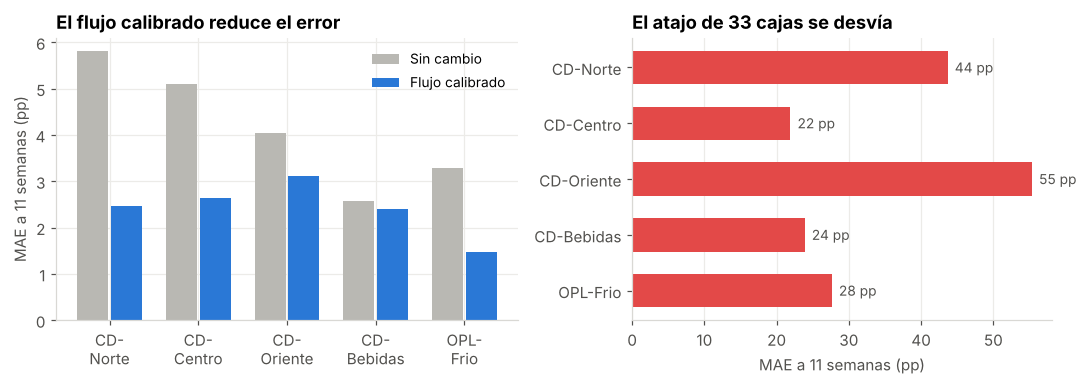

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]; x = np.arange(len(orden)); w = 0.38
ax.bar(x - w/2, resumen_bt["mae_sin_cambio"], w * 0.92, color="#b9b8b3", label="Sin cambio")
ax.bar(x + w/2, resumen_bt["mae_flujo"], w * 0.92, color="#2a78d6", label="Flujo calibrado")
ax.set_xticks(x, [c.replace("-", "-\n") for c in orden]); ax.set_ylabel("MAE a 11 semanas (pp)")
ax.set_title("El flujo calibrado reduce el error"); ax.legend(fontsize=9)
ax = axes[1]
ax.barh(orden[::-1], resumen_bt["mae_atajo_33"][::-1], color="#e34948", height=0.6)
for i, v in enumerate(resumen_bt["mae_atajo_33"][::-1]):
    ax.text(v + 1, i, f"{v:.0f} pp", va="center", color=TINTA2, fontsize=9)
ax.set_xlabel("MAE a 11 semanas (pp)"); ax.set_title("El atajo de 33 cajas se desvía"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(IMG / "backtest.png"); plt.show()

In [17]:
# ¿Por qué falla el atajo? Relación real entre cajas recibidas y bultos despachados
rel = historico.groupby("cd").apply(lambda g: (g["cajas_real"].sum() / (g["piezas_real"].sum() / ppb[g.name])),
                                    include_groups=False)
pd.DataFrame({"cajas_por_bulto_real": rel, "cajas_por_posicion_calibradas": parametros["cajas_por_posicion"]}).loc[orden].round(2)

,cajas_por_bulto_real,cajas_por_posicion_calibradas
cd,,
CD-Norte,1.14,58.27
CD-Centro,1.08,48.04
CD-Oriente,1.21,47.00
CD-Bebidas,1.07,95.14
OPL-Frio,1.10,54.79


### Conclusión: ¿qué método usar?

**El flujo calibrado.** A 11 semanas su error medio es de 1,5 a 3,1 puntos, frente a 2,6 a 5,8 del supuesto "sin cambio", y su sesgo está entre −2,2 y +2,6 puntos. En CD-Bebidas la mejora es pequeña (2,4 frente a 2,6), porque su ocupación varía poco.

**El atajo de 33 cajas no sirve.** Su error va de 22 a 55 puntos y siempre sobrestima la ocupación (sesgo igual al error). La idea de "entra menos sale" es correcta, pero sus dos supuestos fallan:

1. Una caja recibida no equivale a un bulto despachado: la relación real va de 1,07 a 1,21 cajas por bulto, y esa diferencia se acumula semana tras semana como inventario que no existe.
2. Una posición no guarda 33 cajas: la calibración da entre 47 y 95, según el centro.

## 6. Proyección de temporada

Cada centro arranca en su ocupación real de la S42 de 2025 y se proyecta con el forecast de octubre. Las posiciones faltantes se calculan contra el 100 % de las posiciones.

In [18]:
# ---------------- 6. Proyección de temporada ----------------
inicio_ocup = historico[(historico["anio"] == 2025) & (historico["semana"] == 42)].set_index("cd")["ocupacion"] * 100

def proyectar(fc, factor_recibo=None):
    filas = []
    for cd_, g in fc.groupby("cd"):
        g = g.sort_values(["anio", "semana"])
        en_rampa = (g["anio"] == 2025) & g["semana"].between(43, 51)
        cajas = g["cajas"] * np.where(en_rampa, factor_recibo[cd_], 1) if factor_recibo is not None else g["cajas"]
        ocup = inicio_ocup[cd_] + (parametros.loc[cd_, "a"] * cajas - parametros.loc[cd_, "b"] * g["piezas"]).cumsum()
        filas.append(pd.DataFrame({"cd": cd_, "anio": g["anio"], "semana": g["semana"], "mes": g["mes"],
                                   "cajas": cajas.round(), "piezas": g["piezas"], "ocupacion": ocup}))
    return pd.concat(filas, ignore_index=True)

def resumen_pico(p):
    idx = p.groupby("cd")["ocupacion"].idxmax()
    r = p.loc[idx, ["cd", "anio", "semana", "ocupacion"]].set_index("cd").loc[orden]
    r["semana_pico"] = r["anio"].astype(str) + "-S" + r["semana"].astype(str).str.zfill(2)
    r["semanas_sobre_100"] = p[p["ocupacion"] > 100].groupby("cd").size().reindex(orden, fill_value=0)
    r["posiciones_faltantes"] = ((r["ocupacion"] - 100).clip(lower=0) / 100 * pos.loc[orden]).round()
    return r[["ocupacion", "semana_pico", "semanas_sobre_100", "posiciones_faltantes"]].rename(columns={"ocupacion": "pico_%"})

proy_base = proyectar(fc_oct)
pico_base = resumen_pico(proy_base)
pico_base.round(1)

,pico_%,semana_pico,semanas_sobre_100,posiciones_faltantes
cd,,,,
CD-Norte,109.9,2025-S51,5,473.0
CD-Centro,87.7,2025-S50,0,0.0
CD-Oriente,68.8,2025-S51,0,0.0
CD-Bebidas,86.9,2025-S48,0,0.0
OPL-Frio,94.4,2025-S51,0,0.0


In [19]:
# Sensibilidad: el recibo real viene superando el forecast en la rampa de temporada.
# Se proyecta el pico con +5 % y +10 % de recibo en S43-S51 (el resto de semanas queda igual).
sensibilidad = {}
for extra in [0, 5, 10]:
    f_ = pd.Series(1 + extra / 100, index=orden)
    sensibilidad[f"+{extra} %"] = resumen_pico(proyectar(fc_oct, f_ if extra else None))
sens = pd.concat({k: v[["pico_%", "posiciones_faltantes"]] for k, v in sensibilidad.items()}, axis=1)
sens.round(1)

+0 %                        +5 %                       +10 %                     
           pico_% posiciones_faltantes pico_% posiciones_faltantes pico_% posiciones_faltantes
cd                                                                                            
CD-Norte    109.9                473.0  120.1                965.0  130.3               1457.0
CD-Centro    87.7                  0.0   97.1                  0.0  106.8                129.0
CD-Oriente   68.8                  0.0   77.8                  0.0   86.9                  0.0
CD-Bebidas   86.9                  0.0   91.1                  0.0   95.6                  0.0
OPL-Frio     94.4                  0.0  103.0                 11.0  111.6                 41.0

In [20]:
# Ocupación de la red: promedio ponderado por posiciones de los centros propios
propios = cds[cds["tipo"] == "Propio"].set_index("cd")["posiciones"]
def ocup_red(p):
    q = p[p["cd"].isin(propios.index)].copy()
    q["pond"] = q["ocupacion"] * q["cd"].map(propios)
    return q.groupby(["anio", "semana"])["pond"].sum() / propios.sum()
red_base, red_10 = ocup_red(proy_base), ocup_red(proyectar(fc_oct, pd.Series(1.10, index=orden)))
for nombre, r in [("forecast", red_base), ("+10 % de recibo", red_10)]:
    a_, s_ = r.idxmax()
    print(f"Red ({nombre}): pico {r.max():.1f} % en {a_}-S{s_:02d}; semanas sobre 100 %: {(r > 100).sum()}")

Red (forecast): pico 95.1 % en 2025-S51; semanas sobre 100 %: 0
Red (+10 % de recibo): pico 113.7 % en 2025-S51; semanas sobre 100 %: 5


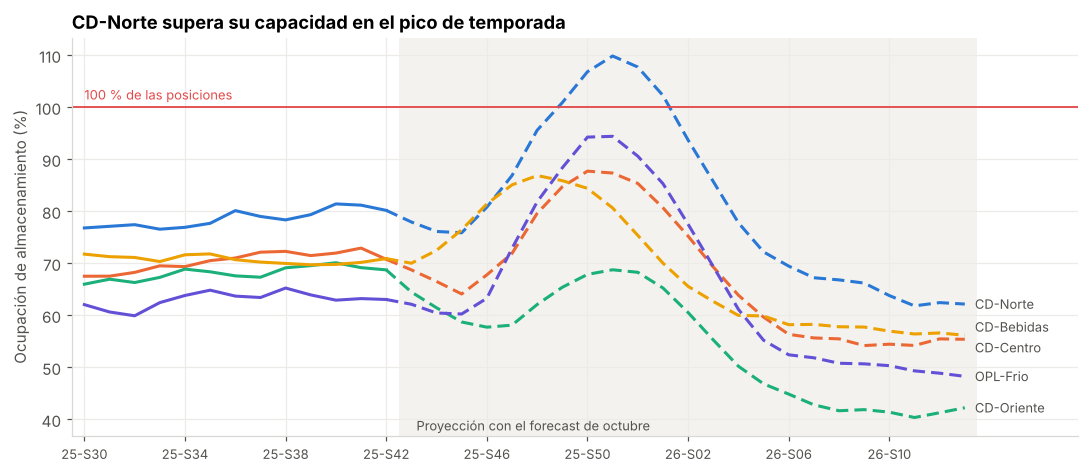

In [21]:
etq = lambda p: p["anio"].astype(str).str[2:] + "-S" + p["semana"].astype(str).str.zfill(2)
fig, ax = plt.subplots(figsize=(10, 4.4))
hist_plot = historico[(historico["anio"] == 2025) & (historico["semana"] >= 30)]
semanas_hist = list(etq(hist_plot[hist_plot["cd"] == "CD-Norte"]))
semanas_proy = list(etq(proy_base[proy_base["cd"] == "CD-Norte"]))
eje = semanas_hist + semanas_proy
for cd_ in orden:
    h = hist_plot[hist_plot["cd"] == cd_]["ocupacion"].values * 100
    p = proy_base[proy_base["cd"] == cd_]["ocupacion"].values
    ax.plot(range(len(h)), h, color=COLORES[cd_], lw=2)
    ax.plot(range(len(h) - 1, len(eje)), np.r_[h[-1], p], color=COLORES[cd_], lw=2, ls=(0, (4, 2)))
    ajuste = {"CD-Bebidas": 1.6, "CD-Centro": -1.6}.get(cd_, 0)
    ax.text(len(eje) - 0.6, p[-1] + ajuste, cd_, color=TINTA2, fontsize=8.5, va="center")
ax.axhline(100, color="#e34948", lw=1.2)
ax.text(0, 101.5, "100 % de las posiciones", color="#e34948", fontsize=8.5)
ax.axvspan(len(semanas_hist) - 0.5, len(eje) - 0.5, color="#f3f2ef", lw=0, zorder=0)
ax.text(len(semanas_hist) + 0.2, ax.get_ylim()[0] + 1, "Proyección con el forecast de octubre", color=TINTA2, fontsize=8.5)
ticks = list(range(0, len(eje), 4)); ax.set_xticks(ticks, [eje[i] for i in ticks], fontsize=8.5)
ax.set_xlim(-0.5, len(eje) + 3.5); ax.set_ylabel("Ocupación de almacenamiento (%)")
ax.set_title("CD-Norte supera su capacidad en el pico de temporada")
plt.tight_layout(); plt.savefig(IMG / "proyeccion_ocupacion.png"); plt.show()

### Conclusión: ¿a qué centro no le alcanza el espacio?

**Solo a CD-Norte: llega a 109,9 % en la S51 y le faltan 473 posiciones durante 5 semanas.** Los demás quedan bajo el 100 %: OPL-Frio 94,4 %, CD-Centro 87,7 %, CD-Bebidas 86,9 % (con un pico adelantado en la S48) y CD-Oriente 68,8 %. La red propia llega a 95,1 % en la S51.

**La sensibilidad cambia el tamaño de la decisión.** Con el recibo subestimado como viene ocurriendo:

| Recibo en S43–S51 | Pico CD-Norte | Posiciones faltantes CD-Norte | Otros centros sobre 100 % |
|---|---|---|---|
| Forecast | 109,9 % | 473 | Ninguno |
| +5 % | 120,1 % | 965 | OPL-Frio (103,0 %) |
| +10 % | 130,3 % | 1.457 | OPL-Frio (111,6 %) y CD-Centro (106,8 %) |

El recibo de CD-Norte viene 12,7 % sobre el forecast en septiembre y octubre, así que el escenario de +10 % es plausible.

## 7. Alistamiento, categorías y versiones del forecast

### 7a. Cubrimiento de alistamiento

Cubrimiento = capacidad semanal de alistamiento ÷ piezas del forecast. Se reporta el mínimo semanal y el total del período.

In [22]:
# ---------------- 7a. Cubrimiento de alistamiento ----------------
cap = cds.set_index("cd")["capacidad_alistamiento_semana"]
cub = fc_oct.assign(cubrimiento=lambda d: 100 * d["cd"].map(cap) / d["piezas"])
cubrimiento = cub.groupby("cd").agg(minimo_semanal=("cubrimiento", "min"))
cubrimiento["total_periodo"] = 100 * (cap * fc_oct.groupby("cd").size()) / fc_oct.groupby("cd")["piezas"].sum()
cubrimiento.loc[orden].round(1)

,minimo_semanal,total_periodo
cd,,
CD-Norte,110.8,126.2
CD-Centro,103.9,117.4
CD-Oriente,107.5,119.4
CD-Bebidas,103.0,116.7
OPL-Frio,100.5,109.5


### Conclusión: ¿alcanza la capacidad de alistamiento?

**Sí, en todos los centros.** El cubrimiento mínimo semanal va de 100,5 % (OPL-Frio) a 110,8 % (CD-Norte), y el total del período de 109,5 % a 126,2 %. El cuello de botella es el almacenamiento, no el alistamiento. El OPL-Frio queda sin holgura en su semana pico.

### 7b. ¿Qué categoría llena CD-Norte?

Cada categoría acumula `cajas − piezas ÷ f`, donde `f` son sus piezas por caja en la S43–S44. La suma por categoría no cuadra exactamente con el modelo total, porque el supuesto de equilibrio en octubre es aproximado. Por eso el aumento de posiciones del modelo se reparte según el neto acumulado de cada categoría.

In [23]:
# ---------------- 7b. Categorías en el centro más crítico ----------------
CRITICO = "CD-Norte"
fc_cat = forecast[(forecast["version"] == "2025-10") & (forecast["cd"] == CRITICO)].sort_values(["anio", "semana"])
base_cat = fc_cat[(fc_cat["anio"] == 2025) & fc_cat["semana"].between(43, 44)].groupby("categoria")[["cajas", "piezas"]].sum()
f_cat = base_cat["piezas"] / base_cat["cajas"]                # piezas por caja de octubre (equilibrio)
K = parametros.loc[CRITICO, "a"] * pos[CRITICO] / 100        # posiciones por caja neta

fc_cat = fc_cat.assign(neto=lambda d: d["cajas"] - d["piezas"] / d["categoria"].map(f_cat))
fc_cat["neto_acum"] = fc_cat.groupby("categoria")["neto"].cumsum()
# El total por categoría no cuadra exactamente con el modelo (el supuesto de equilibrio es aproximado):
# se reparte el aumento de posiciones del modelo según el neto acumulado de cada categoría.
total_modelo = (proy_base[proy_base["cd"] == CRITICO].set_index(["anio", "semana"])["ocupacion"] - inicio_ocup[CRITICO]) / 100 * pos[CRITICO]
suma_neto = fc_cat.groupby(["anio", "semana"])["neto_acum"].transform("sum")
fc_cat["posiciones_acum"] = fc_cat["neto_acum"] / suma_neto * fc_cat.set_index(["anio", "semana"]).index.map(total_modelo)
pico_sem = proy_base[proy_base["cd"] == CRITICO].loc[lambda d: d["ocupacion"].idxmax(), ["anio", "semana"]]
en_pico = fc_cat[(fc_cat["anio"] == pico_sem["anio"]) & (fc_cat["semana"] == pico_sem["semana"])].set_index("categoria")

temp = fc_cat[(fc_cat["anio"] == 2025) & fc_cat["semana"].between(45, 51)].groupby("categoria")["cajas"].mean()
octu = fc_cat[(fc_cat["anio"] == 2025) & fc_cat["semana"].between(43, 44)].groupby("categoria")["cajas"].mean()
categorias = pd.DataFrame({
    "participacion_recibo_temporada_%": 100 * temp / temp.sum(),
    "var_recibo_vs_octubre_%": 100 * (temp / octu - 1),
    "posiciones_acumuladas_en_pico": en_pico["posiciones_acum"],
}).sort_values("posiciones_acumuladas_en_pico", ascending=False)
pico_total = total_modelo.max()
sin_reparto = (en_pico["neto_acum"] * K).sum()
print(f"Aumento de posiciones en el pico (modelo total): {pico_total:.0f}")
print(f"Suma por categoría sin reconciliar: {sin_reparto:.0f} ({100 * (sin_reparto / pico_total - 1):+.0f} %)")
categorias.round(1)

Aumento de posiciones en el pico (modelo total): 1424
Suma por categoría sin reconciliar: 2304 (+62 %)


,participacion_recibo_temporada_%,var_recibo_vs_octubre_%,posiciones_acumuladas_en_pico
categoria,,,
Snacks,36.2,59.9,592.1
Bebidas,20.4,35.4,267.6
Licores y fiesta,12.9,91.7,248.0
Abarrotes,14.1,27.7,168.5
Comida preparada,7.5,24.6,84.2
Cuidado personal,5.6,10.4,33.0
Insumos,3.2,25.6,30.8


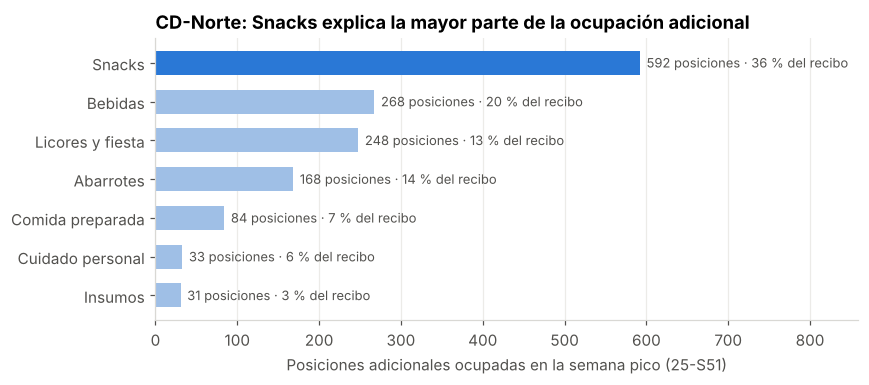

In [24]:
sem_pico = f"{pico_sem['anio'] % 100}-S{pico_sem['semana']:02d}"
d = categorias.sort_values("posiciones_acumuladas_en_pico")
fig, ax = plt.subplots(figsize=(8, 3.6))
colores_bar = ["#2a78d6" if c == d.index[-1] else "#9fbfe6" for c in d.index]
ax.barh(d.index, d["posiciones_acumuladas_en_pico"], color=colores_bar, height=0.62)
for i, (v, sh) in enumerate(zip(d["posiciones_acumuladas_en_pico"], d["participacion_recibo_temporada_%"])):
    ax.text(v + 8, i, f"{v:.0f} posiciones · {sh:.0f} % del recibo", va="center", color=TINTA2, fontsize=8.5)
ax.set_xlim(0, d["posiciones_acumuladas_en_pico"].max() * 1.45); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Posiciones adicionales ocupadas en la semana pico ({sem_pico})")
ax.set_title(f"{CRITICO}: {d.index[-1]} explica la mayor parte de la ocupación adicional")
plt.tight_layout(); plt.savefig(IMG / "posiciones_por_categoria.png"); plt.show()

### Conclusión

**Snacks explica 592 posiciones en la semana pico, más que todo el faltante base (473).** Es el 36 % del recibo de temporada y crece 60 % frente a octubre. Licores y fiesta es la categoría que más crece (+92 %), pero pesa menos. Snacks es la candidata natural para la bodega adicional.

### 7c. ¿Qué cambió entre versiones del forecast?

In [25]:
# ---------------- 7c. Versiones del forecast ----------------
tot = forecast.groupby(["version", "cd", "anio", "semana", "mes"], as_index=False)[["cajas", "piezas"]].sum()
comun = tot[tot["anio"] == 2025]
v = comun.pivot_table(index=["cd", "mes"], columns="version", values="cajas", aggfunc="sum")
v["desviacion_%"] = 100 * (v["2025-10"] / v["2025-09"] - 1)
print(v.round(1))

pico_sep = resumen_pico(proyectar(tot[tot["version"] == "2025-09"]))
pico_oct_2025 = resumen_pico(proy_base[proy_base["anio"] == 2025])
pd.DataFrame({"pico_sep_%": pico_sep["pico_%"], "pico_oct_%": pico_oct_2025["pico_%"]}).round(1)

version          2025-09   2025-10  desviacion_%
cd         mes                                  
CD-Bebidas 10    29176.0   33344.0          14.3
           11    77608.0   88089.0          13.5
           12    46257.0   51924.0          12.3
CD-Centro  10    30117.0   30117.0           0.0
           11    81962.0   81962.0           0.0
           12    81722.0   81722.0           0.0
CD-Norte   10    83505.0   94561.0          13.2
           11   234319.0  264897.0          13.0
           12   234227.0  265928.0          13.5
CD-Oriente 10    19899.0   19899.0           0.0
           11    47962.0   47962.0           0.0
           12    55682.0   55682.0           0.0
OPL-Frio   10     5117.0    5117.0           0.0
           11    16068.0   16068.0           0.0
           12    14393.0   14393.0           0.0


,pico_sep_%,pico_oct_%
cd,,
CD-Norte,86.1,109.9
CD-Centro,87.7,87.7
CD-Oriente,68.6,68.8
CD-Bebidas,76.9,86.9
OPL-Frio,94.5,94.4


### Conclusión

**La versión de octubre subió el recibo de CD-Norte (+13 %) y de CD-Bebidas (+12 % a +14 %); los demás centros no cambiaron.** Con la versión de septiembre, CD-Norte llegaba a 86,1 % y no tenía faltante. Una actualización del forecast cambió la decisión, así que la proyección se debe repetir con cada versión.

## 8. Semáforo de la red

**Crítico:** pico sobre 100 % con el forecast. **Alerta:** pico sobre 100 % solo con +10 % de recibo. **En control:** el resto. Las tablas finales quedan en `outputs/` para el Excel de soporte.

In [26]:
# ---------------- Tablas para el dashboard y el Excel ----------------
proy_base.assign(escenario="Forecast").to_csv(OUT / "proyeccion_forecast.csv", index=False)
historico.to_csv(OUT / "historico_limpio.csv", index=False)
cumplimiento.to_csv(OUT / "cumplimiento_mensual.csv", index=False)
resumen_bt.to_csv(OUT / "backtest_resumen.csv")
parametros.to_csv(OUT / "parametros.csv")
semaforo_red = (pico_base.join(sens[("+10 %", "pico_%")].rename("pico_+10%_recibo"))
                .join(cubrimiento).join(inicio_ocup.rename("ocupacion_hoy_%")))
semaforo_red["estado"] = np.select([semaforo_red["pico_%"] > 100, semaforo_red["pico_+10%_recibo"] > 100],
                                   ["Crítico", "Alerta"], "En control")
semaforo_red.to_csv(OUT / "semaforo.csv")
semaforo_red[["ocupacion_hoy_%", "pico_%", "semana_pico", "posiciones_faltantes", "pico_+10%_recibo", "minimo_semanal", "estado"]].round(1)

,ocupacion_hoy_%,pico_%,semana_pico,posiciones_faltantes,pico_+10%_recibo,minimo_semanal,estado
cd,,,,,,,
CD-Norte,80.2,109.9,2025-S51,473.0,130.3,110.8,Crítico
CD-Centro,70.8,87.7,2025-S50,0.0,106.8,103.9,Alerta
CD-Oriente,68.8,68.8,2025-S51,0.0,86.9,107.5,En control
CD-Bebidas,70.9,86.9,2025-S48,0.0,95.6,103.0,En control
OPL-Frio,63.1,94.4,2025-S51,0.0,111.6,100.5,Alerta


## Resumen ejecutivo

| Centro | Estado | Pico con forecast | Posiciones faltantes | Pico con +10 % de recibo |
|---|---|---|---|---|
| CD-Norte | Crítico | 109,9 % (S51) | 473 | 130,3 % |
| CD-Centro | Alerta | 87,7 % (S50) | 0 | 106,8 % |
| OPL-Frio | Alerta | 94,4 % (S51) | 0 | 111,6 % |
| CD-Bebidas | En control | 86,9 % (S48) | 0 | 95,6 % |
| CD-Oriente | En control | 68,8 % (S51) | 0 | 86,9 % |

- **El recibo crece cuatro veces más que el alistamiento** (+21,6 % frente a +5,3 %), y el forecast de recibo viene por debajo del real.
- **El flujo calibrado es un método confiable:** error de 1,5 a 3,1 puntos a 11 semanas. El atajo de 33 cajas se equivoca entre 22 y 55 puntos.
- **La limitante es el almacenamiento:** la capacidad de alistamiento cubre la demanda en todos los centros.

## Recomendaciones

1. **CD-Norte:** contratar entre 950 y 1.450 posiciones adicionales entre la S48 de 2025 y la S03 de 2026. El rango cubre el recibo con +5 % y +10 % sobre el forecast. Definir la cifra final con el cumplimiento de noviembre.
2. **Bodega adicional:** trasladar primero Snacks, que ocupa cerca de 600 posiciones en el pico.
3. **CD-Centro y OPL-Frio:** seguimiento semanal del recibo real y posiciones de contingencia acordadas con el operador desde la S47.
4. **Planeación:** conciliar el forecast de recibo de temporada, que viene entre 6 % y 13 % por debajo del real.
5. **Método:** descartar el atajo de 33 cajas por ubicación y repetir la proyección con cada versión del forecast.

## Limitaciones

- El modelo supone que la relación entre recibo, alistamiento y ocupación se mantiene en temporada; ajustes operativos como traslados o bajas no están modelados.
- La sensibilidad aplica el mismo porcentaje a todos los centros y solo en la rampa (S43–S51).
- El reparto por categoría supone equilibrio en octubre; con la ocupación real por categoría del WMS el cálculo sería directo.
- Los datos son sintéticos: las cifras ilustran el método, no una operación real.